# Comparative Analysis: MHE-MPC with Profile Likelihood Calculation
This notebook evaluates and plots **Profile Likelihood (PL)** results for the full measurement horizon.
The initial parameter values are loaded from `Set_up_general.py` (via `initial_para`), which are defined in log10 space.

It plots the Profile Likelihood for each parameter over the parameter range.


In [1]:
# add path 
from pathlib import Path 
import sys 

# Dynamically resolve project root containing solver_config.py 
project_root = Path.cwd().resolve() 
while project_root != project_root.parent and not (project_root / "solver_config.py").exists(): 
    project_root = project_root.parent 

if str(project_root) not in sys.path: 
    sys.path.insert(0, str(project_root)) 

# set up 
from Set_up_general import * # for all relevant other files - general setup + figures 


CasADi - 2026-10-20 09:27:45 WARNING("The options 't0', 'tf', 'grid' and 'output_t0' have been deprecated.
The same functionality is provided by providing additional input arguments to the 'integrator' function, in particular:
 * Call integrator(..., t0, tf, options) for a single output time, or
 * Call integrator(..., t0, grid, options) for multiple grid points.
The legacy 'output_t0' option can be emulated by including or excluding 't0' in 'grid'.
Backwards compatibility is provided in this release only.") [.../casadi/core/integrator.cpp:692]


load data MPC

In [2]:
# Load comparison results from dataset_PL.npz
data = np.load("dataset_PL.npz")

var_para_full =  data['var_para_full']
Y_measurements =data['Y_measurements']
para_opt=data['para_opt']
PL_broken= data['PL_broken']
Obj_tk = data['Obj_tk']
Obj_opt = data['Obj_opt']
Conf_Int=data['Conf_Int']
    

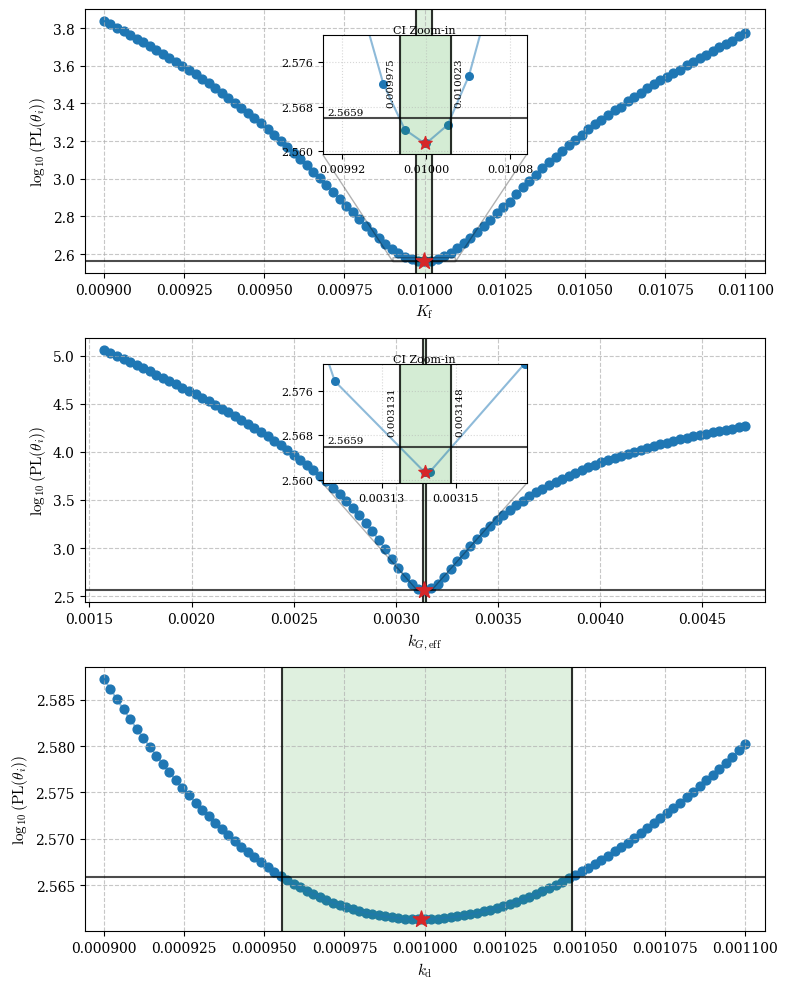

In [3]:
nice_plot_PL(
    p=p,
    Para=var_para_full,
    Para_opt=para_opt,
    Obj=Obj_tk,
    Obj_opt=Obj_opt,
    CI=Conf_Int,
    PL_broken=PL_broken,
    save_name='PL_full_data.png'
)